# Classification-HAM10000

Clasificarea leziunilor cutanate din imagini dermatoscopice cu rețele
neuronale convoluționale și augmentare generativă a claselor minoritare

**Celula 1: Importuri si configurare**

In [10]:
import os
import glob
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.model_selection import train_test_split
from tqdm import tqdm


# Alegem processing unit-ul (cuda pe Kaggle / cpu / mps pe laptopul meu (MacBook M1))
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print('Device:', device)

# Pe Kaggle setul de date este montat in /kaggle/input
ON_KAGGLE = os.path.exists('/kaggle/input')
DATA_DIR = '/kaggle/input' if ON_KAGGLE else './data'

batch_size = 64
img_size = 224 # dimensiunea de intrare pentru ResNet-18
random_seed = 1

# Numarul de procese care incarca datele in paralel (decodarea JPEG 600x450 & redimensionarea se fac pe CPU)
# Pe MacBook, in Jupyter, procesele auxiliare nu gasesc clasele definite in notebook, voi folosi 0
num_workers = 4 if ON_KAGGLE else 0

# Ordinea fixa a claselor (indexul din lista = eticheta numerica)
CLASSES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
CLASS_NAMES = {
    'akiec': 'Keratoza actinica / carcinom intraepitelial',
    'bcc':   'Carcinom bazocelular',
    'bkl':   'Keratoza benigna',
    'df':    'Dermatofibrom',
    'mel':   'Melanom',
    'nv':    'Nev melanocitar',
    'vasc':  'Leziuni vasculare',
}
class_to_idx = {c: i for i, c in enumerate(CLASSES)}

Device: cpu


**Celula 2: Incarcarea metadatelor**

In [11]:
def load_metadata(data_dir):
    # Caut recursiv fisierul de metadate si imaginile, ca sa nu depind de structura exacta a folderelor
    csv_paths = glob.glob(os.path.join(data_dir, '**', 'HAM10000_metadata.csv'), recursive=True)
    if not csv_paths:
        raise FileNotFoundError(f'Nu am gasit HAM10000_metadata.csv in {data_dir}')
    metadata = pd.read_csv(csv_paths[0])

    # Imaginile sunt impartite in doua foldere (part_1 si part_2). 
    # Pe Kaggle apar si dubluri in foldere cu nume diferite
    # Dictionarul pastreaza o singura cale pentru fiecare image_id
    image_paths = {os.path.splitext(os.path.basename(p))[0]: p
                   for p in glob.glob(os.path.join(data_dir, '**', '*.jpg'), recursive=True)}
    metadata['path'] = metadata['image_id'].map(image_paths)

    missing = metadata['path'].isna().sum()
    if missing > 0:
        raise FileNotFoundError(f'{missing} imagini din metadate nu au fost gasite pe disc')

    metadata['label'] = metadata['dx'].map(class_to_idx)
    return metadata


metadata = load_metadata(DATA_DIR)
print(f'{len(metadata)} imagini, {metadata["lesion_id"].nunique()} leziuni unice')
print(metadata['dx'].value_counts())
metadata.head()

10015 imagini, 7470 leziuni unice
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


,lesion_id,image_id,dx,dx_type,age,sex,localization,path,label
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/kaggle/input/datasets/kmader/skin-cancer-mnis...,2


**Celula 3: Impartirea train/val/test la nivel de leziune**

In [12]:
def make_splits(metadata, valid_size=0.15, test_size=0.15, random_seed=1):
    # Aceeasi leziune apare adesea in mai multe imagini. Impart dupa lesion_id, nu dupa imagine.
    assert metadata.groupby('lesion_id')['dx'].nunique().max() == 1, 'O leziune are mai multe diagnostice'
    lesions = metadata.drop_duplicates('lesion_id')[['lesion_id', 'dx']]

    # Stratificare dupa diagnostic: fiecare split pastreaza distributia claselor
    train_les, rest_les = train_test_split(lesions,
                                           test_size=valid_size + test_size,
                                           stratify=lesions['dx'],
                                           random_state=random_seed)
    valid_les, test_les = train_test_split(rest_les,
                                           test_size=test_size / (valid_size + test_size),
                                           stratify=rest_les['dx'],
                                           random_state=random_seed)

    split_of = {}
    for name, part in [('train', train_les), ('val', valid_les), ('test', test_les)]:
        split_of.update(dict.fromkeys(part['lesion_id'], name))

    df = metadata.copy()
    df['split'] = df['lesion_id'].map(split_of)
    return df


df = make_splits(metadata, valid_size=0.15, test_size=0.15, random_seed=random_seed)

# Verific faptul ca nicio leziune nu apare in doua split-uri
les = {s: set(df.loc[df['split'] == s, 'lesion_id']) for s in ['train', 'val', 'test']}
assert not (les['train'] & les['val']) and not (les['train'] & les['test']) and not (les['val'] & les['test'])

# Proportiile la nivel de imagine pot diferi putin de 70/15/15, deoarece clasele au numar diferit de imagini
print(df['split'].value_counts(normalize=True).round(3), '\n')
print(pd.crosstab(df['dx'], df['split'], margins=True)[['train', 'val', 'test', 'All']])

# Salvez impartirea, ca toate experimentele sa foloseasca exact aceleasi split-uri
df[['image_id', 'lesion_id', 'dx', 'split']].to_csv('splits.csv', index=False)

split
train    0.704
test     0.149
val      0.148
Name: proportion, dtype: float64 

split  train   val  test    All
dx                             
akiec    230    53    44    327
bcc      356    78    80    514
bkl      751   165   183   1099
df        82    15    18    115
mel      786   156   171   1113
nv      4743   992   970   6705
vasc      99    21    22    142
All     7047  1480  1488  10015


**Celula 4: Clasa Dataset**

In [14]:
class HAM10000Dataset(Dataset):
    def __init__(self, df, transform=None):
        self.paths = df['path'].tolist()
        self.labels = df['label'].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert('RGB')
        if self.transform is not None:
            image = self.transform(image)
        return image, self.labels[idx]

**Celula 5: Normalizare, transformari si DataLoaders**

In [17]:
# Statisticile ImageNet - folosite cu retele preantrenate pe ImageNet (ResNet-18)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def compute_mean_std(train_df, img_size, batch_size=64, num_workers=0):
    # Ca in laborator: medie si deviatie standard pe canal, calculate DOAR pe imaginile de antrenare
    dataset = HAM10000Dataset(train_df, transform=transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
    ]))
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=num_workers)

    n_pixels = 0
    s = torch.zeros(3, dtype=torch.float64)
    s2 = torch.zeros(3, dtype=torch.float64)
    for images, _ in tqdm(loader, desc='mean/std'):
        images = images.double()
        n_pixels += images.numel() // images.size(1)
        s += images.sum(dim=(0, 2, 3))
        s2 += (images ** 2).sum(dim=(0, 2, 3))
    mean = s / n_pixels
    std = (s2 / n_pixels - mean ** 2).sqrt()
    return mean.tolist(), std.tolist()


def get_loaders(df,
                batch_size,
                augment,
                normalization='imagenet', # 'imagenet' (retea preantrenata) / 'dataset' (retea de la zero)
                weighted_sampling=False,
                img_size=224,
                num_workers=0):

    train_df = df[df['split'] == 'train']
    valid_df = df[df['split'] == 'val']
    test_df = df[df['split'] == 'test']

    if normalization == 'imagenet':
        mean, std = IMAGENET_MEAN, IMAGENET_STD
    else:
        mean, std = compute_mean_std(train_df, img_size, batch_size, num_workers)
    print(f'Normalization ({normalization}): mean = {mean}, std = {std}')
    normalize = transforms.Normalize(mean=mean, std=std)

    # Definesc setul de transformari necesare bazei de date
    valid_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)), # imaginile originale au 600x450
        transforms.ToTensor(),
        normalize,
    ])
    if augment:
        train_transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.RandomHorizontalFlip(), # leziunile nu au o orientare "corecta",
            transforms.RandomVerticalFlip(),   # deci oglindirile pe ambele axe sunt valide
            transforms.RandomRotation(20),
            transforms.ColorJitter(brightness=0.1, contrast=0.1), # fara hue: culoarea conteaza in diagnostic
            transforms.ToTensor(),
            normalize,
        ])
    else:
        train_transform = valid_transform

    # Transformari identice cu cele pentru validare, normalizare cu aceleasi valori ca la train
    test_transform = valid_transform

    train_dataset = HAM10000Dataset(train_df, train_transform)
    valid_dataset = HAM10000Dataset(valid_df, valid_transform)
    test_dataset = HAM10000Dataset(test_df, test_transform)

    loader_args = dict(batch_size=batch_size,
                       num_workers=num_workers,
                       persistent_workers=num_workers > 0,
                       pin_memory=torch.cuda.is_available())

    if weighted_sampling:
        # Fiecare imagine primeste o pondere invers proportionala cu frecventa clasei sale.
        # Astfel incat clasele rare apar in batch-uri aproximativ la fel de des ca cele frecvente
        class_counts = np.bincount(train_df['label'], minlength=len(CLASSES))
        sample_weights = 1.0 / class_counts[train_df['label'].values]
        sampler = WeightedRandomSampler(torch.as_tensor(sample_weights, dtype=torch.double),
                                        num_samples=len(train_df), replacement=True)
        train_loader = DataLoader(train_dataset, sampler=sampler, **loader_args)
    else:
        train_loader = DataLoader(train_dataset, shuffle=True, **loader_args)

    # La evaluare nu este nevoie de amestecarea datelor
    valid_loader = DataLoader(valid_dataset, shuffle=False, **loader_args)
    test_loader = DataLoader(test_dataset, shuffle=False, **loader_args)

    return train_loader, valid_loader, test_loader


train_loader, valid_loader, test_loader = get_loaders(
    df,
    batch_size=batch_size,
    augment=True,
    normalization='imagenet',
    weighted_sampling=False,
    img_size=img_size,
    num_workers=num_workers,
)

Normalization (imagenet): mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225]


**Celula 6: Verificare DataLoaders**

train:  7047 imagini, 111 batch-uri
val  :  1480 imagini,  24 batch-uri
test :  1488 imagini,  24 batch-uri
Batch imagini: (64, 3, 224, 224) torch.float32
Batch etichete: (64,) torch.int64
Clase in batch: {'akiec': 0, 'bcc': 3, 'bkl': 5, 'df': 1, 'mel': 10, 'nv': 44, 'vasc': 1}


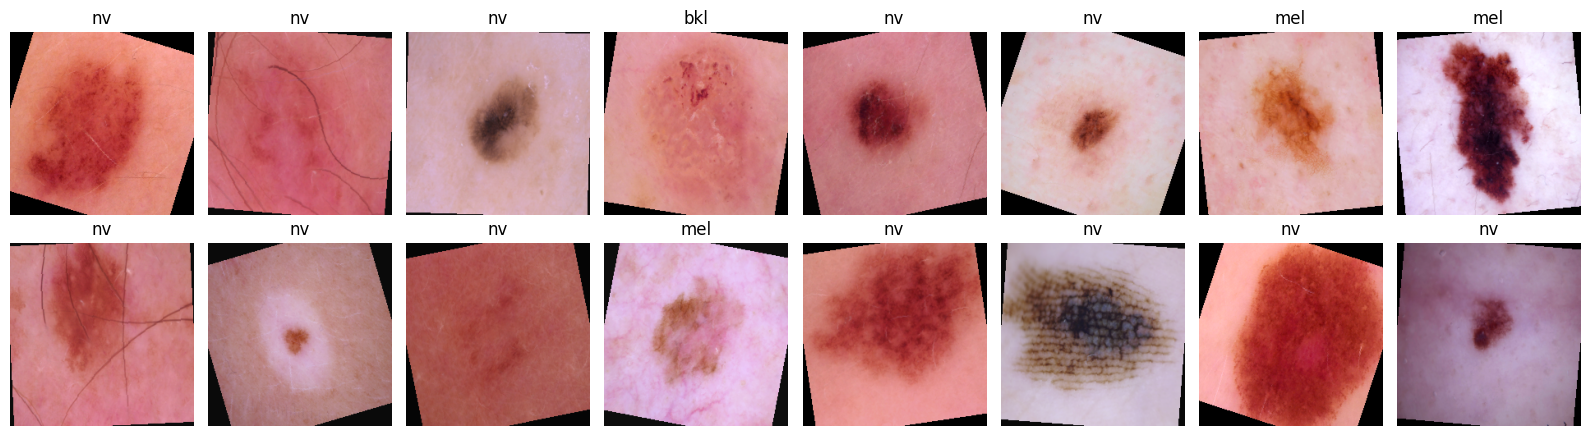

train pass: 100%|██████████| 111/111 [00:36<00:00,  3.06it/s]

O epoca de incarcare a datelor: 36.2 s


In [18]:
for name, loader in [('train', train_loader), ('val', valid_loader), ('test', test_loader)]:
    print(f'{name:5s}: {len(loader.dataset):5d} imagini, {len(loader):3d} batch-uri')

images, labels = next(iter(train_loader))
print('Batch imagini:', tuple(images.shape), images.dtype)
print('Batch etichete:', tuple(labels.shape), labels.dtype)
print('Clase in batch:', {CLASSES[i]: int(c) for i, c in enumerate(torch.bincount(labels, minlength=len(CLASSES)))})


def show_batch(images, labels, loader, n=16):
    # Inversez normalizarea pentru afisare (Normalize este ultima transformare)
    norm = loader.dataset.transform.transforms[-1]
    mean = torch.tensor(norm.mean).view(3, 1, 1)
    std = torch.tensor(norm.std).view(3, 1, 1)
    fig, axes = plt.subplots(2, n // 2, figsize=(2 * n // 2, 4.5))
    for ax, img, lbl in zip(axes.flat, images[:n], labels[:n]):
        ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
        ax.set_title(CLASSES[lbl])
        ax.axis('off')
    plt.tight_layout()
    plt.show()


show_batch(images, labels, train_loader)

# O trecere completa prin train (verifica faptul ca toate imaginile se incarca si masoara viteza)
start = time.time()
for images, labels in tqdm(train_loader, desc='train pass'):
    pass
print(f'O epoca de incarcare a datelor: {time.time() - start:.1f} s')